In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
import warnings

from pathlib import Path

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [2]:

if Path.cwd().name.lower() == "notebooks":
    PROJECT_PATH = Path.cwd().parent
else:
    PROJECT_PATH = Path.cwd()

RAW_PATH = PROJECT_PATH / "data" / "raw"
PROCESSED_PATH = PROJECT_PATH / "data" / "processed"
MODEL_PATH = PROJECT_PATH / "models"
REPORT_PATH = PROJECT_PATH / "reports" / "model_evaluation"

PROCESSED_PATH.mkdir(parents=True, exist_ok=True)
MODEL_PATH.mkdir(parents=True, exist_ok=True)
REPORT_PATH.mkdir(parents=True, exist_ok=True)

print("Project path:", PROJECT_PATH)
print("Raw data path:", RAW_PATH)

Project path: c:\my prsnl\Luminar\Luminar_Project\FlightWise_AI
Raw data path: c:\my prsnl\Luminar\Luminar_Project\FlightWise_AI\data\raw


In [3]:
for year in range(2018, 2023):
    file_path = RAW_PATH / f"Combined_Flights_{year}.parquet"

    if file_path.exists():
        print(year, "Dataset found")
    else:
        print(year, "Dataset missing:", file_path)

2018 Dataset found
2019 Dataset found
2020 Dataset found
2021 Dataset found
2022 Dataset found


In [4]:
SAMPLE_SIZE = 100_000

COLUMNS = [
    "FlightDate", "Airline", "Origin", "Dest",
    "Cancelled", "Diverted",
    "CRSDepTime", "CRSArrTime",
    "Distance", "ArrDelayMinutes"
]

yearly_data = {}

for year in range(2018, 2023):
    file_path = RAW_PATH / f"Combined_Flights_{year}.parquet"

    yearly_df = pd.read_parquet(file_path, columns=COLUMNS)

    yearly_df = yearly_df.sample(
        n=min(SAMPLE_SIZE, len(yearly_df)),
        random_state=42
    )

    yearly_df["DatasetYear"] = year
    yearly_data[year] = yearly_df

    print(year, yearly_df.shape)

2018 (100000, 11)
2019 (100000, 11)
2020 (100000, 11)
2021 (100000, 11)
2022 (100000, 11)


In [5]:
df = pd.concat(yearly_data.values(), ignore_index=True)

print("Combined dataset shape:", df.shape)
df.head()

Combined dataset shape: (500000, 11)


,FlightDate,Airline,Origin,Dest,Cancelled,Diverted,CRSDepTime,CRSArrTime,Distance,ArrDelayMinutes,DatasetYear
0,2018-03-24,Hawaiian Airlines Inc.,LIH,HNL,False,False,1900,1935,102.0,0.0,2018
1,2018-04-23,Endeavor Air Inc.,BOS,PIT,False,False,2055,2249,496.0,27.0,2018
2,2018-02-16,Southwest Airlines Co.,HOU,ECP,False,False,1650,1820,571.0,43.0,2018
3,2018-12-07,Southwest Airlines Co.,MDW,MCO,False,False,1845,2215,990.0,0.0,2018
4,2018-06-03,Southwest Airlines Co.,LAS,LIT,False,False,1200,1655,1294.0,0.0,2018


In [6]:
df.head()

,FlightDate,Airline,Origin,Dest,Cancelled,Diverted,CRSDepTime,CRSArrTime,Distance,ArrDelayMinutes,DatasetYear
0,2018-03-24,Hawaiian Airlines Inc.,LIH,HNL,False,False,1900,1935,102.0,0.0,2018
1,2018-04-23,Endeavor Air Inc.,BOS,PIT,False,False,2055,2249,496.0,27.0,2018
2,2018-02-16,Southwest Airlines Co.,HOU,ECP,False,False,1650,1820,571.0,43.0,2018
3,2018-12-07,Southwest Airlines Co.,MDW,MCO,False,False,1845,2215,990.0,0.0,2018
4,2018-06-03,Southwest Airlines Co.,LAS,LIT,False,False,1200,1655,1294.0,0.0,2018


In [7]:
df.tail()

,FlightDate,Airline,Origin,Dest,Cancelled,Diverted,CRSDepTime,CRSArrTime,Distance,ArrDelayMinutes,DatasetYear
499995,2022-04-06,Comair Inc.,CLT,ORF,False,False,1610,1724,290.0,6.0,2022
499996,2022-02-10,Envoy Air,ORD,MKE,False,False,1050,1152,67.0,0.0,2022
499997,2022-07-24,United Air Lines Inc.,DEN,SMF,False,False,2117,2250,909.0,94.0,2022
499998,2022-04-28,United Air Lines Inc.,EWR,MCO,False,False,1205,1447,937.0,0.0,2022
499999,2022-03-24,Delta Air Lines Inc.,MSP,SEA,False,False,1100,1235,1399.0,0.0,2022


In [8]:
df.shape

(500000, 11)

In [9]:
df.columns

Index(['FlightDate', 'Airline', 'Origin', 'Dest', 'Cancelled', 'Diverted',
       'CRSDepTime', 'CRSArrTime', 'Distance', 'ArrDelayMinutes',
       'DatasetYear'],
      dtype='str')

In [10]:
df.dtypes

FlightDate         datetime64[us]
Airline                       str
Origin                        str
Dest                          str
Cancelled                    bool
Diverted                     bool
CRSDepTime                  int64
CRSArrTime                  int64
Distance                  float64
ArrDelayMinutes           float64
DatasetYear                 int64
dtype: object

In [11]:
df.isnull().sum()

FlightDate             0
Airline                0
Origin                 0
Dest                   0
Cancelled              0
Diverted               0
CRSDepTime             0
CRSArrTime             0
Distance               0
ArrDelayMinutes    15447
DatasetYear            0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
FlightDate,500000,NaN,NaN,NaN,2020-06-20 07:53:25.900800,2018-01-01 00:00:00,2019-04-05 00:00:00,2020-06-02 00:00:00,2021-10-10 00:00:00,2022-07-31 00:00:00,NaN
Airline,500000,28,Southwest Airlines Co.,94448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Origin,500000,387,ATL,23631,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dest,500000,387,ATL,23329,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cancelled,500000,2,False,485731,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Diverted,500000,2,False,498832,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CRSDepTime,500000.0,NaN,NaN,NaN,1326.035174,1.0,917.0,1320.0,1730.0,2359.0,481.990943
CRSArrTime,500000.0,NaN,NaN,NaN,1488.92476,1.0,1109.0,1515.0,1915.0,2400.0,507.01845
Distance,500000.0,NaN,NaN,NaN,781.581618,29.0,356.0,628.0,1017.0,5095.0,582.783548
ArrDelayMinutes,484553.0,NaN,NaN,NaN,12.738316,0.0,0.0,0.0,6.0,2522.0,45.61515


In [14]:
columns_to_check = ["Airline", "Origin", "Dest", "Cancelled", "Diverted"]

for column in columns_to_check:
    print("\n", column)
    print("Unique values:", df[column].nunique())
    print(df[column].value_counts().head(10))


 Airline
Unique values: 28
Airline
Southwest Airlines Co.    94448
Delta Air Lines Inc.      56294
SkyWest Airlines Inc.     54261
American Airlines Inc.    53216
United Air Lines Inc.     40569
Republic Airlines         22048
JetBlue Airways           18967
Envoy Air                 18137
Endeavor Air Inc.         17284
Comair Inc.               16167
Name: count, dtype: int64

 Origin
Unique values: 387
Origin
ATL    23631
ORD    23504
DEN    20257
DFW    18815
CLT    15406
LAX    14253
SEA    12476
IAH    11803
PHX    11620
LAS    11507
Name: count, dtype: int64

 Dest
Unique values: 387
Dest
ATL    23329
ORD    23225
DEN    20366
DFW    18843
CLT    15399
LAX    14246
SEA    12490
PHX    11729
IAH    11725
LAS    11663
Name: count, dtype: int64

 Cancelled
Unique values: 2
Cancelled
False    485731
True      14269
Name: count, dtype: int64

 Diverted
Unique values: 2
Diverted
False    498832
True       1168
Name: count, dtype: int64


In [15]:
df["DatasetYear"].value_counts().sort_index()

DatasetYear
2018    100000
2019    100000
2020    100000
2021    100000
2022    100000
Name: count, dtype: int64

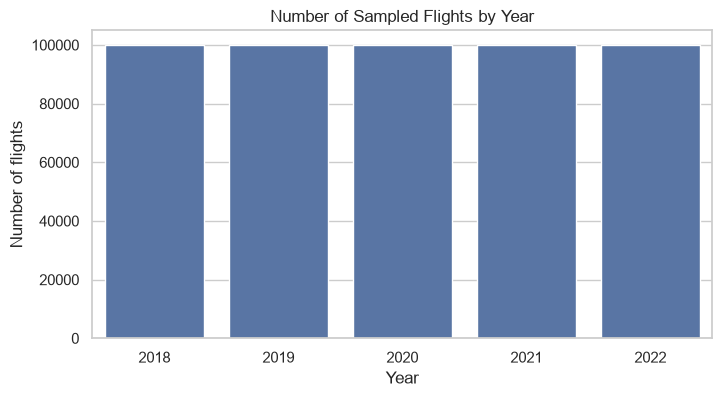

In [16]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="DatasetYear")
plt.title("Number of Sampled Flights by Year")
plt.xlabel("Year")
plt.ylabel("Number of flights")
plt.show()

In [17]:
print("Rows before cleaning:", len(df))

df = df[
    (df["Cancelled"] == False) &
    (df["Diverted"] == False) &
    (df["ArrDelayMinutes"].notna())
].copy()

df["FlightDate"] = pd.to_datetime(df["FlightDate"], errors="coerce")
df = df[df["FlightDate"].notna()].copy()

df["Delayed"] = (df["ArrDelayMinutes"] >= 15).astype(int)

print("Rows after cleaning:", len(df))
print("Delayed flights:", (df["Delayed"] == 1).sum())
print("Not delayed flights:", (df["Delayed"] == 0).sum())

Rows before cleaning: 500000
Rows after cleaning: 484553
Delayed flights: 85239
Not delayed flights: 399314


In [18]:
df["Delayed"].value_counts()

Delayed
0    399314
1     85239
Name: count, dtype: int64

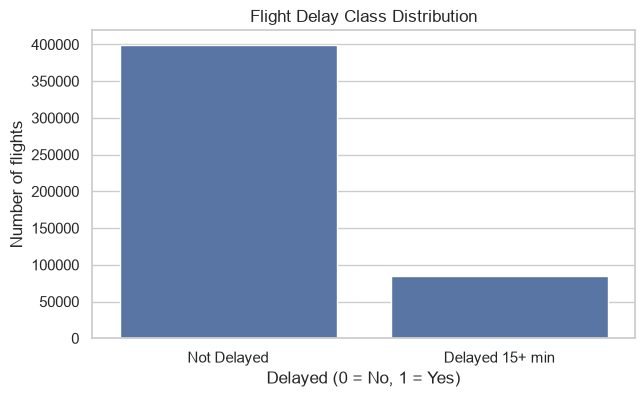

In [19]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Delayed")
plt.title("Flight Delay Class Distribution")
plt.xlabel("Delayed (0 = No, 1 = Yes)")
plt.ylabel("Number of flights")
plt.xticks([0, 1], ["Not Delayed", "Delayed 15+ min"])
plt.show()

In [20]:
delay_percentage = df["Delayed"].value_counts(normalize=True) * 100
delay_percentage

Delayed
0    82.408735
1    17.591265
Name: proportion, dtype: float64

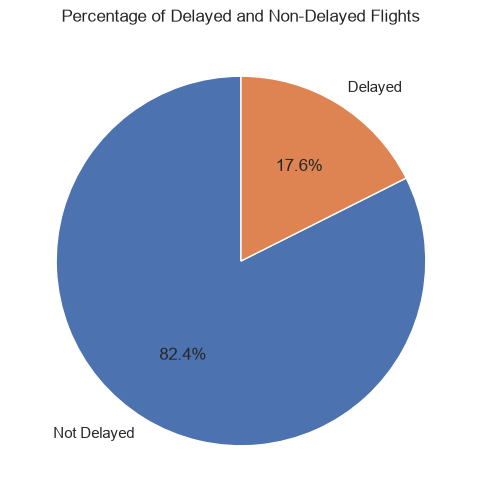

In [21]:
plt.figure(figsize=(6, 6))
plt.pie(
    delay_percentage.values,
    labels=["Not Delayed", "Delayed"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Percentage of Delayed and Non-Delayed Flights")
plt.show()

In [22]:
year_delay = (
    df.groupby("DatasetYear")["Delayed"]
    .mean()
    .mul(100)
    .reset_index(name="Delay_Rate")
)

year_delay

,DatasetYear,Delay_Rate
0,2018,19.503228
1,2019,19.380859
2,2020,9.941315
3,2021,17.253003
4,2022,21.607292


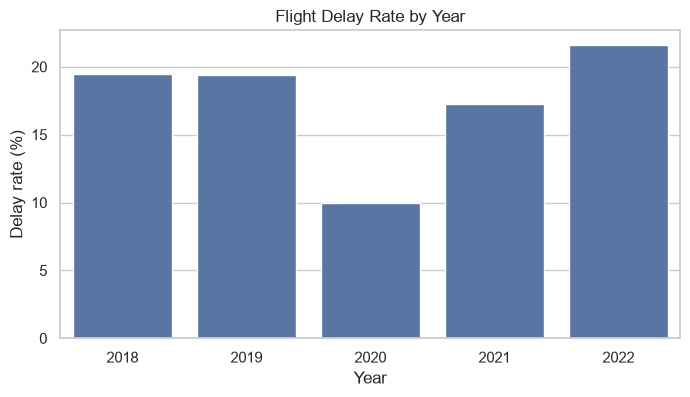

In [23]:
plt.figure(figsize=(8, 4))
sns.barplot(data=year_delay, x="DatasetYear", y="Delay_Rate")
plt.title("Flight Delay Rate by Year")
plt.xlabel("Year")
plt.ylabel("Delay rate (%)")
plt.show()

In [24]:
df["Month"] = df["FlightDate"].dt.month

month_delay = (
    df.groupby("Month")["Delayed"]
    .mean()
    .mul(100)
    .reset_index(name="Delay_Rate")
)

month_delay

,Month,Delay_Rate
0,1,16.029918
1,2,18.921414
2,3,15.765888
3,4,16.622793
4,5,18.218046
5,6,22.295372
6,7,21.024686
7,8,19.332418
8,9,13.371607
9,10,15.219762


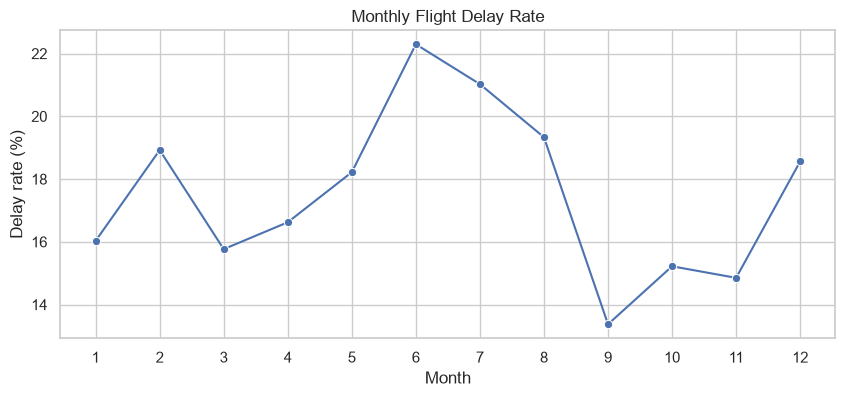

In [25]:
plt.figure(figsize=(10, 4))
sns.lineplot(data=month_delay, x="Month", y="Delay_Rate", marker="o")
plt.xticks(range(1, 13))
plt.title("Monthly Flight Delay Rate")
plt.xlabel("Month")
plt.ylabel("Delay rate (%)")
plt.show()

In [26]:
airline_delay = (
    df.groupby("Airline")["Delayed"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .reset_index(name="Delay_Rate")
)

airline_delay

,Airline,Delay_Rate
0,Peninsula Airways Inc.,28.888889
1,Allegiant Air,25.925473
2,JetBlue Airways,25.720983
3,Frontier Airlines Inc.,25.354700
4,"Commutair Aka Champlain Enterprises, Inc.",24.795895
5,Trans States Airlines,24.791667
6,ExpressJet Airlines Inc.,21.054586
7,"GoJet Airlines, LLC d/b/a United Express",20.026207
8,Spirit Air Lines,19.369401
9,Empire Airlines Inc.,18.769231


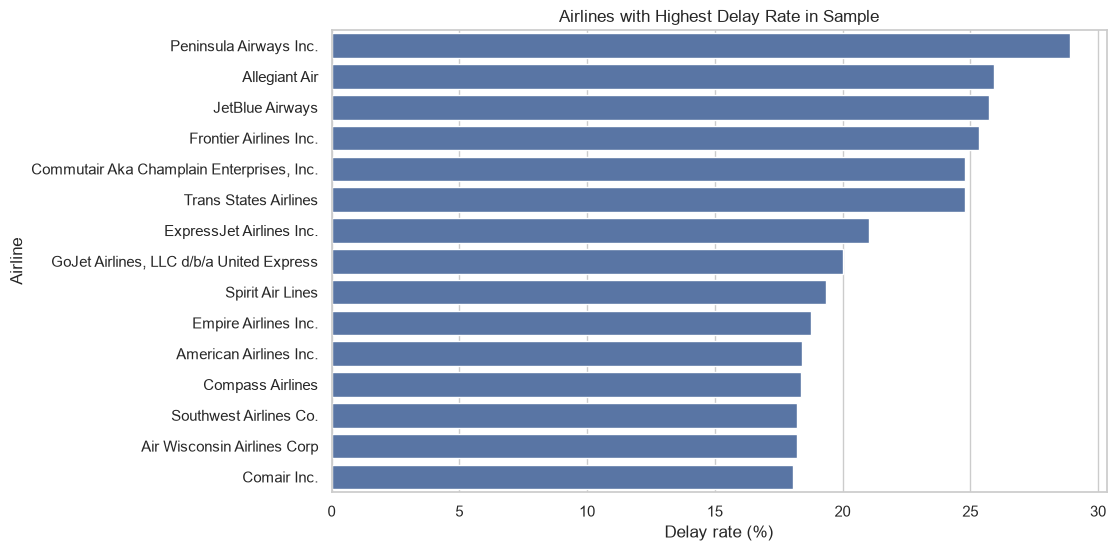

In [27]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=airline_delay.sort_values("Delay_Rate", ascending=False).head(15),
    x="Delay_Rate",
    y="Airline"
)
plt.title("Airlines with Highest Delay Rate in Sample")
plt.xlabel("Delay rate (%)")
plt.ylabel("Airline")
plt.show()

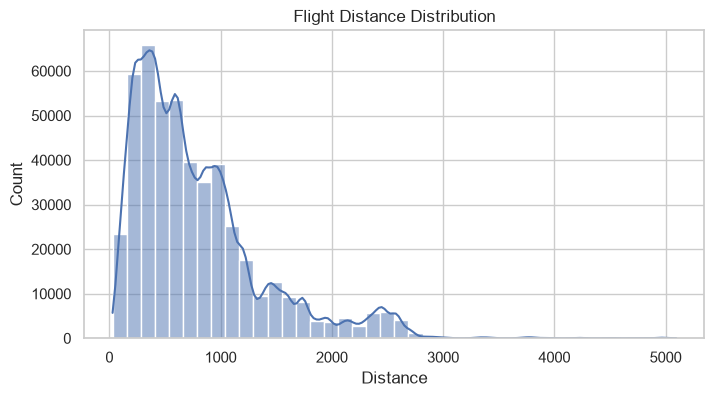

In [28]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="Distance", bins=40, kde=True)
plt.title("Flight Distance Distribution")
plt.xlabel("Distance")
plt.show()

In [30]:
df["DepHour"] = (df["CRSDepTime"] // 100).clip(upper=23)
hour_delay = (
    df.groupby("DepHour")["Delayed"]
    .mean()
    .mul(100)
    .reset_index(name="Delay_Rate")
)

hour_delay

,DepHour,Delay_Rate
0,0,19.646799
1,1,16.847826
2,2,28.800000
3,3,26.595745
4,4,14.285714
5,5,8.194557
6,6,9.265243
7,7,11.038961
8,8,12.509010
9,9,13.142838


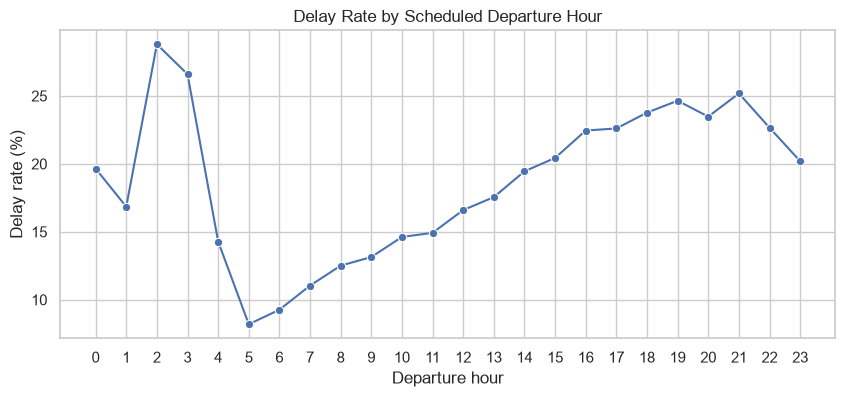

In [31]:
plt.figure(figsize=(10, 4))
sns.lineplot(data=hour_delay, x="DepHour", y="Delay_Rate", marker="o")
plt.xticks(range(0, 24))
plt.title("Delay Rate by Scheduled Departure Hour")
plt.xlabel("Departure hour")
plt.ylabel("Delay rate (%)")
plt.show()

In [32]:
model_data = df[
    [
        "FlightDate", "Airline", "Origin", "Dest",
        "CRSDepTime", "CRSArrTime", "Distance",
        "Delayed", "DatasetYear"
    ]
].copy()

model_data.head()

,FlightDate,Airline,Origin,Dest,CRSDepTime,CRSArrTime,Distance,Delayed,DatasetYear
0,2018-03-24,Hawaiian Airlines Inc.,LIH,HNL,1900,1935,102.0,0,2018
1,2018-04-23,Endeavor Air Inc.,BOS,PIT,2055,2249,496.0,1,2018
2,2018-02-16,Southwest Airlines Co.,HOU,ECP,1650,1820,571.0,1,2018
3,2018-12-07,Southwest Airlines Co.,MDW,MCO,1845,2215,990.0,0,2018
4,2018-06-03,Southwest Airlines Co.,LAS,LIT,1200,1655,1294.0,0,2018


In [33]:
train_data = model_data[model_data["DatasetYear"].isin([2018, 2019, 2020])].copy()
val_data = model_data[model_data["DatasetYear"] == 2021].copy()
test_data = model_data[model_data["DatasetYear"] == 2022].copy()

print("Training data:", train_data.shape)
print("Validation data:", val_data.shape)
print("Test data:", test_data.shape)

Training data: (289898, 9)
Validation data: (97896, 9)
Test data: (96759, 9)


In [34]:
print("Training target:")
print(train_data["Delayed"].value_counts())

print("\nValidation target:")
print(val_data["Delayed"].value_counts())

print("\nTest target:")
print(test_data["Delayed"].value_counts())

Training target:
Delayed
0    242456
1     47442
Name: count, dtype: int64

Validation target:
Delayed
0    81006
1    16890
Name: count, dtype: int64

Test target:
Delayed
0    75852
1    20907
Name: count, dtype: int64


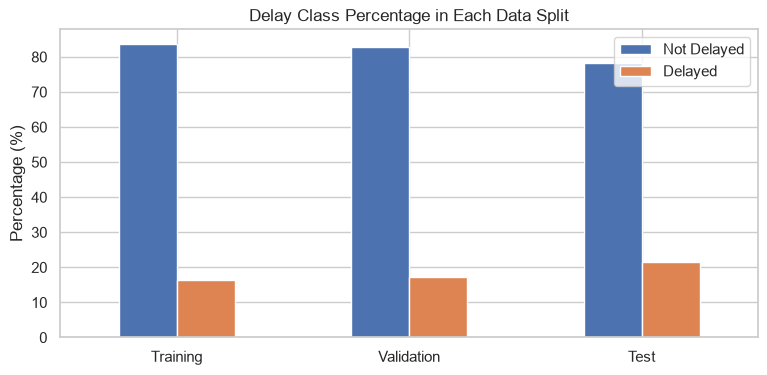

In [35]:
split_counts = pd.DataFrame({
    "Training": train_data["Delayed"].value_counts(normalize=True),
    "Validation": val_data["Delayed"].value_counts(normalize=True),
    "Test": test_data["Delayed"].value_counts(normalize=True)
}).T * 100

split_counts.plot(kind="bar", figsize=(9, 4))
plt.title("Delay Class Percentage in Each Data Split")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(["Not Delayed", "Delayed"])
plt.show()

In [36]:
def create_features(data):
    data = data.copy()

    data["FlightDate"] = pd.to_datetime(data["FlightDate"])

    data["Year"] = data["FlightDate"].dt.year
    data["Month"] = data["FlightDate"].dt.month
    data["Day"] = data["FlightDate"].dt.day
    data["DayOfWeek"] = data["FlightDate"].dt.dayofweek
    data["DayOfYear"] = data["FlightDate"].dt.dayofyear
    data["IsWeekend"] = data["DayOfWeek"].isin([5, 6]).astype(int)

    data["DepHour"] = data["CRSDepTime"] // 100
    data["DepMinute"] = data["CRSDepTime"] % 100
    data["ArrHour"] = data["CRSArrTime"] // 100
    data["ArrMinute"] = data["CRSArrTime"] % 100

    data["DepHour"] = data["DepHour"].replace(24, 0)
    data["ArrHour"] = data["ArrHour"].replace(24, 0)

                                                                   
    departure_minutes = data["DepHour"] * 60 + data["DepMinute"]
    arrival_minutes = data["ArrHour"] * 60 + data["ArrMinute"]
    data["ScheduledDuration"] = arrival_minutes - departure_minutes
    data.loc[data["ScheduledDuration"] < 0, "ScheduledDuration"] += 1440

                                                                                      
    data["DepHourSin"] = np.sin(2 * np.pi * data["DepHour"] / 24)
    data["DepHourCos"] = np.cos(2 * np.pi * data["DepHour"] / 24)
    data["MonthSin"] = np.sin(2 * np.pi * data["Month"] / 12)
    data["MonthCos"] = np.cos(2 * np.pi * data["Month"] / 12)

    return data

In [37]:
train_data = create_features(train_data)
val_data = create_features(val_data)
test_data = create_features(test_data)

train_data.head()

,FlightDate,Airline,Origin,Dest,CRSDepTime,CRSArrTime,Distance,Delayed,DatasetYear,Year,Month,Day,DayOfWeek,DayOfYear,IsWeekend,DepHour,DepMinute,ArrHour,ArrMinute,ScheduledDuration,DepHourSin,DepHourCos,MonthSin,MonthCos
0,2018-03-24,Hawaiian Airlines Inc.,LIH,HNL,1900,1935,102.0,0,2018,2018,3,24,5,83,1,19,0,19,35,35,-9.659258e-01,2.588190e-01,1.000000e+00,6.123234e-17
1,2018-04-23,Endeavor Air Inc.,BOS,PIT,2055,2249,496.0,1,2018,2018,4,23,0,113,0,20,55,22,49,114,-8.660254e-01,5.000000e-01,8.660254e-01,-5.000000e-01
2,2018-02-16,Southwest Airlines Co.,HOU,ECP,1650,1820,571.0,1,2018,2018,2,16,4,47,0,16,50,18,20,90,-8.660254e-01,-5.000000e-01,8.660254e-01,5.000000e-01
3,2018-12-07,Southwest Airlines Co.,MDW,MCO,1845,2215,990.0,0,2018,2018,12,7,4,341,0,18,45,22,15,210,-1.000000e+00,-1.836970e-16,-2.449294e-16,1.000000e+00
4,2018-06-03,Southwest Airlines Co.,LAS,LIT,1200,1655,1294.0,0,2018,2018,6,3,6,154,1,12,0,16,55,295,1.224647e-16,-1.000000e+00,1.224647e-16,-1.000000e+00


In [38]:
def get_period(hour):
    if pd.isna(hour):
        return "Unknown"
    elif hour < 6:
        return "Night"
    elif hour < 12:
        return "Morning"
    elif hour < 18:
        return "Afternoon"
    else:
        return "Evening"

train_data["DepPeriod"] = train_data["DepHour"].apply(get_period)
val_data["DepPeriod"] = val_data["DepHour"].apply(get_period)
test_data["DepPeriod"] = test_data["DepHour"].apply(get_period)

train_data[["DepHour", "DepPeriod"]].head(10)

,DepHour,DepPeriod
0,19,Evening
1,20,Evening
2,16,Afternoon
3,18,Evening
4,12,Afternoon
5,10,Morning
6,10,Morning
7,8,Morning
8,10,Morning
9,15,Afternoon


In [39]:
FEATURES = [
    "Airline", "Origin", "Dest",
    "Distance", "ScheduledDuration",
    "Year", "Month", "Day", "DayOfWeek", "DayOfYear", "IsWeekend",
    "DepHour", "DepMinute", "ArrHour", "ArrMinute",
    "DepHourSin", "DepHourCos", "MonthSin", "MonthCos",
    "DepPeriod"
]

TARGET = "Delayed"

X_train = train_data[FEATURES].copy()
y_train = train_data[TARGET].copy()

X_val = val_data[FEATURES].copy()
y_val = val_data[TARGET].copy()

X_test = test_data[FEATURES].copy()
y_test = test_data[TARGET].copy()

print("Input features:", FEATURES)
print("Number of input features:", len(FEATURES))

Input features: ['Airline', 'Origin', 'Dest', 'Distance', 'ScheduledDuration', 'Year', 'Month', 'Day', 'DayOfWeek', 'DayOfYear', 'IsWeekend', 'DepHour', 'DepMinute', 'ArrHour', 'ArrMinute', 'DepHourSin', 'DepHourCos', 'MonthSin', 'MonthCos', 'DepPeriod']
Number of input features: 20


In [40]:
categorical_features = [
    "Airline", "Origin", "Dest", "DepPeriod"
]

numerical_features = [
    "Distance", "ScheduledDuration", "Year", "Month", "Day",
    "DayOfWeek", "DayOfYear", "IsWeekend",
    "DepHour", "DepMinute", "ArrHour", "ArrMinute",
    "DepHourSin", "DepHourCos", "MonthSin", "MonthCos"
]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['Airline', 'Origin', 'Dest', 'DepPeriod']
Numerical features: ['Distance', 'ScheduledDuration', 'Year', 'Month', 'Day', 'DayOfWeek', 'DayOfYear', 'IsWeekend', 'DepHour', 'DepMinute', 'ArrHour', 'ArrMinute', 'DepHourSin', 'DepHourCos', 'MonthSin', 'MonthCos']


In [41]:
numeric_imputer = SimpleImputer(strategy="median")

X_train_num = pd.DataFrame(
    numeric_imputer.fit_transform(X_train[numerical_features]),
    columns=numerical_features,
    index=X_train.index
)

X_val_num = pd.DataFrame(
    numeric_imputer.transform(X_val[numerical_features]),
    columns=numerical_features,
    index=X_val.index
)

X_test_num = pd.DataFrame(
    numeric_imputer.transform(X_test[numerical_features]),
    columns=numerical_features,
    index=X_test.index
)

X_train_num.isnull().sum()

Distance             0
ScheduledDuration    0
Year                 0
Month                0
Day                  0
DayOfWeek            0
DayOfYear            0
IsWeekend            0
DepHour              0
DepMinute            0
ArrHour              0
ArrMinute            0
DepHourSin           0
DepHourCos           0
MonthSin             0
MonthCos             0
dtype: int64

In [42]:
scaler = StandardScaler()

X_train_num = pd.DataFrame(
    scaler.fit_transform(X_train_num),
    columns=numerical_features,
    index=X_train.index
)

X_val_num = pd.DataFrame(
    scaler.transform(X_val_num),
    columns=numerical_features,
    index=X_val.index
)

X_test_num = pd.DataFrame(
    scaler.transform(X_test_num),
    columns=numerical_features,
    index=X_test.index
)

X_train_num.head()

,Distance,ScheduledDuration,Year,Month,Day,DayOfWeek,DayOfYear,IsWeekend,DepHour,DepMinute,ArrHour,ArrMinute,DepHourSin,DepHourCos,MonthSin,MonthCos
0,-1.156849,-1.020654,-1.210468,-1.010802,0.944955,1.018981,-0.942424,1.641772,1.254566,-1.487804,0.874522,0.328254,-1.176954,1.207911,1.440510,-0.124053
1,-0.475947,-0.248102,-1.210468,-0.733133,0.830903,-1.476824,-0.669965,-0.609098,1.463084,1.551012,1.466067,1.129455,-1.044181,1.662509,1.252991,-0.844771
2,-0.346333,-0.482801,-1.210468,-1.288472,0.032542,0.519820,-1.269375,-0.609098,0.629010,1.274756,0.677341,-0.530176,-1.044181,-0.222375,1.252991,0.596665
3,0.377774,0.690694,-1.210468,1.488225,-0.993922,0.519820,1.400725,-0.609098,1.046047,0.998500,1.466067,-0.816319,-1.222240,0.720067,0.040846,1.317383
4,0.903141,1.521920,-1.210468,-0.177793,-1.450128,1.518142,-0.297604,1.641772,-0.205065,-1.487804,0.282978,1.472827,0.106810,-1.164817,0.040846,-1.565489


In [43]:
categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train_cat = pd.DataFrame(
    categorical_imputer.fit_transform(X_train[categorical_features]),
    columns=categorical_features,
    index=X_train.index
)

X_val_cat = pd.DataFrame(
    categorical_imputer.transform(X_val[categorical_features]),
    columns=categorical_features,
    index=X_val.index
)

X_test_cat = pd.DataFrame(
    categorical_imputer.transform(X_test[categorical_features]),
    columns=categorical_features,
    index=X_test.index
)

X_train_cat.head()

,Airline,Origin,Dest,DepPeriod
0,Hawaiian Airlines Inc.,LIH,HNL,Evening
1,Endeavor Air Inc.,BOS,PIT,Evening
2,Southwest Airlines Co.,HOU,ECP,Afternoon
3,Southwest Airlines Co.,MDW,MCO,Evening
4,Southwest Airlines Co.,LAS,LIT,Afternoon


In [44]:
X_train_ready = pd.concat([X_train_num, X_train_cat], axis=1)
X_val_ready = pd.concat([X_val_num, X_val_cat], axis=1)
X_test_ready = pd.concat([X_test_num, X_test_cat], axis=1)

X_train_ready.head()

,Distance,ScheduledDuration,Year,Month,Day,DayOfWeek,DayOfYear,IsWeekend,DepHour,DepMinute,ArrHour,ArrMinute,DepHourSin,DepHourCos,MonthSin,MonthCos,Airline,Origin,Dest,DepPeriod
0,-1.156849,-1.020654,-1.210468,-1.010802,0.944955,1.018981,-0.942424,1.641772,1.254566,-1.487804,0.874522,0.328254,-1.176954,1.207911,1.440510,-0.124053,Hawaiian Airlines Inc.,LIH,HNL,Evening
1,-0.475947,-0.248102,-1.210468,-0.733133,0.830903,-1.476824,-0.669965,-0.609098,1.463084,1.551012,1.466067,1.129455,-1.044181,1.662509,1.252991,-0.844771,Endeavor Air Inc.,BOS,PIT,Evening
2,-0.346333,-0.482801,-1.210468,-1.288472,0.032542,0.519820,-1.269375,-0.609098,0.629010,1.274756,0.677341,-0.530176,-1.044181,-0.222375,1.252991,0.596665,Southwest Airlines Co.,HOU,ECP,Afternoon
3,0.377774,0.690694,-1.210468,1.488225,-0.993922,0.519820,1.400725,-0.609098,1.046047,0.998500,1.466067,-0.816319,-1.222240,0.720067,0.040846,1.317383,Southwest Airlines Co.,MDW,MCO,Evening
4,0.903141,1.521920,-1.210468,-0.177793,-1.450128,1.518142,-0.297604,1.641772,-0.205065,-1.487804,0.282978,1.472827,0.106810,-1.164817,0.040846,-1.565489,Southwest Airlines Co.,LAS,LIT,Afternoon


In [45]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTraining class percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

Training class distribution:
Delayed
0    242456
1     47442
Name: count, dtype: int64

Training class percentages:
Delayed
0    83.63
1    16.37
Name: proportion, dtype: float64


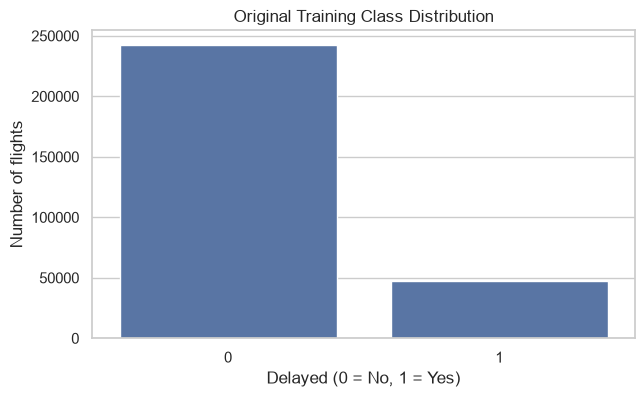

In [46]:
plt.figure(figsize=(7, 4))
sns.countplot(x=y_train)
plt.title("Original Training Class Distribution")
plt.xlabel("Delayed (0 = No, 1 = Yes)")
plt.ylabel("Number of flights")
plt.show()

In [47]:
X_train_encoded = pd.get_dummies(
    X_train_ready,
    columns=categorical_features
)

X_val_encoded = pd.get_dummies(
    X_val_ready,
    columns=categorical_features
)

X_test_encoded = pd.get_dummies(
    X_test_ready,
    columns=categorical_features
)

X_val_encoded = X_val_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("Training shape:", X_train_encoded.shape)
print("Validation shape:", X_val_encoded.shape)
print("Test shape:", X_test_encoded.shape)

Training shape: (289898, 810)
Validation shape: (97896, 810)
Test shape: (96759, 810)


In [48]:
print("Missing values in training:", X_train_encoded.isnull().sum().sum())
print("Missing values in validation:", X_val_encoded.isnull().sum().sum())
print("Missing values in test:", X_test_encoded.isnull().sum().sum())

X_train_encoded.head()

Missing values in training: 0
Missing values in validation: 0
Missing values in test: 0


,Distance,ScheduledDuration,Year,Month,Day,DayOfWeek,DayOfYear,IsWeekend,DepHour,DepMinute,ArrHour,ArrMinute,DepHourSin,DepHourCos,MonthSin,MonthCos,Airline_Air Wisconsin Airlines Corp,Airline_Alaska Airlines Inc.,Airline_Allegiant Air,Airline_American Airlines Inc.,Airline_Cape Air,Airline_Capital Cargo International,Airline_Comair Inc.,"Airline_Commutair Aka Champlain Enterprises, Inc.",Airline_Compass Airlines,Airline_Delta Air Lines Inc.,Airline_Empire Airlines Inc.,Airline_Endeavor Air Inc.,Airline_Envoy Air,Airline_ExpressJet Airlines Inc.,Airline_Frontier Airlines Inc.,"Airline_GoJet Airlines, LLC d/b/a United Express",Airline_Hawaiian Airlines Inc.,Airline_Horizon Air,Airline_JetBlue Airways,Airline_Mesa Airlines Inc.,Airline_Peninsula Airways Inc.,Airline_Republic Airlines,Airline_SkyWest Airlines Inc.,Airline_Southwest Airlines Co.,Airline_Spirit Air Lines,Airline_Trans States Airlines,Airline_United Air Lines Inc.,Airline_Virgin America,Origin_ABE,Origin_ABI,Origin_ABQ,Origin_ABR,Origin_ABY,Origin_ACK,Origin_ACT,Origin_ACV,Origin_ACY,Origin_ADK,Origin_ADQ,Origin_AEX,Origin_AGS,Origin_AKN,Origin_ALB,Origin_ALO,Origin_ALS,Origin_ALW,Origin_AMA,Origin_ANC,Origin_APN,Origin_ART,Origin_ASE,Origin_ATL,Origin_ATW,Origin_ATY,Origin_AUS,Origin_AVL,Origin_AVP,Origin_AZA,Origin_AZO,Origin_BDL,Origin_BET,Origin_BFF,Origin_BFL,Origin_BFM,Origin_BGM,Origin_BGR,Origin_BHM,Origin_BIL,Origin_BIS,Origin_BJI,Origin_BKG,Origin_BLI,Origin_BLV,Origin_BMI,Origin_BNA,Origin_BOI,Origin_BOS,Origin_BPT,Origin_BQK,Origin_BQN,Origin_BRD,Origin_BRO,Origin_BRW,Origin_BTM,Origin_BTR,Origin_BTV,Origin_BUF,Origin_BUR,Origin_BWI,Origin_BZN,Origin_CAE,Origin_CAK,Origin_CDB,Origin_CDC,Origin_CDV,Origin_CGI,Origin_CHA,Origin_CHO,Origin_CHS,Origin_CID,Origin_CIU,Origin_CKB,Origin_CLE,Origin_CLL,Origin_CLT,Origin_CMH,Origin_CMI,Origin_CMX,Origin_CNY,Origin_COD,Origin_COS,Origin_COU,Origin_CPR,Origin_CRP,Origin_CRW,Origin_CSG,Origin_CVG,Origin_CWA,Origin_CYS,Origin_DAB,Origin_DAL,Origin_DAY,Origin_DBQ,Origin_DCA,Origin_DDC,Origin_DEC,Origin_DEN,Origin_DFW,Origin_DHN,Origin_DIK,Origin_DLG,Origin_DLH,Origin_DRO,Origin_DRT,Origin_DSM,Origin_DTW,Origin_DUT,Origin_DVL,Origin_EAR,Origin_EAT,Origin_EAU,Origin_ECP,Origin_EGE,Origin_EKO,Origin_ELM,Origin_ELP,Origin_ERI,Origin_ESC,Origin_EUG,Origin_EVV,Origin_EWN,Origin_EWR,Origin_EYW,Origin_FAI,Origin_FAR,Origin_FAT,Origin_FAY,Origin_FCA,Origin_FLG,Origin_FLL,Origin_FLO,Origin_FNT,Origin_FSD,Origin_FSM,Origin_FWA,Origin_GCC,Origin_GCK,Origin_GEG,Origin_GFK,Origin_GGG,Origin_GJT,Origin_GNV,Origin_GPT,Origin_GRB,Origin_GRI,Origin_GRK,Origin_GRR,Origin_GSO,Origin_GSP,Origin_GST,Origin_GTF,Origin_GTR,Origin_GUC,Origin_GUM,Origin_HDN,Origin_HGR,Origin_HHH,Origin_HIB,Origin_HLN,Origin_HNL,Origin_HOB,Origin_HOU,Origin_HPN,Origin_HRL,Origin_HSV,Origin_HTS,Origin_HVN,Origin_HYA,Origin_HYS,Origin_IAD,Origin_IAG,Origin_IAH,Origin_ICT,Origin_IDA,Origin_ILM,Origin_IMT,Origin_IND,Origin_INL,Origin_IPT,Origin_ISN,Origin_ISP,Origin_ITH,Origin_ITO,Origin_JAC,Origin_JAN,Origin_JAX,Origin_JFK,Origin_JHM,Origin_JLN,Origin_JMS,Origin_JNU,Origin_KOA,Origin_KTN,Origin_LAN,Origin_LAR,Origin_LAS,Origin_LAW,Origin_LAX,Origin_LBB,Origin_LBE,Origin_LBF,Origin_LBL,Origin_LCH,Origin_LCK,Origin_LEX,Origin_LFT,Origin_LGA,Origin_LGB,Origin_LIH,Origin_LIT,Origin_LNK,Origin_LNY,Origin_LRD,Origin_LSE,Origin_LWB,Origin_LWS,Origin_LYH,Origin_MAF,Origin_MBS,Origin_MCI,Origin_MCO,Origin_MDT,Origin_MDW,Origin_MEI,Origin_MEM,Origin_MFE,Origin_MFR,Origin_MGM,Origin_MHK,Origin_MHT,Origin_MIA,Origin_MKE,Origin_MKG,Origin_MKK,Origin_MLB,Origin_MLI,Origin_MLU,Origin_MMH,Origin_MOB,Origin_MOT,Origin_MQT,Origin_MRY,Origin_MSN,Origin_MSO,Origin_MSP,Origin_MSY,Origin_MTJ,Origin_MVY,Origin_MYR,Origin_OAJ,Origin_OAK,Origin_OGD,Origin_OGG,Origin_OGS,Origin_OKC,Origin_OMA,Origin_OME,Origin_ONT,Origin_ORD,Origin_ORF,Origin_ORH,Origin_OTH,Origin_OTZ,Origin_OWB,Origin_PAE,Origin_PAH,Origin_PBG,Origin_PBI,Origin_PDX,Origin_PGD,Origin_PGV,Origin_PHF,Origin_PHL,Origin_PHX,Or

In [49]:
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_encoded, y_train)

log_val_prob = log_model.predict_proba(X_val_encoded)[:, 1]
log_val_pred = (log_val_prob >= 0.5).astype(int)

print("Logistic Regression trained.")

Logistic Regression trained.


In [50]:
dt_model = DecisionTreeClassifier(
    max_depth=15,
    min_samples_leaf=20,
    random_state=42
)

dt_model.fit(X_train_encoded, y_train)

dt_val_prob = dt_model.predict_proba(X_val_encoded)[:, 1]
dt_val_pred = (dt_val_prob >= 0.5).astype(int)

print("Decision Tree trained.")

Decision Tree trained.


In [51]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=18,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_encoded, y_train)

rf_val_prob = rf_model.predict_proba(X_val_encoded)[:, 1]
rf_val_pred = (rf_val_prob >= 0.5).astype(int)

print("Random Forest trained.")

Random Forest trained.


In [52]:
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_encoded, y_train)

xgb_val_prob = xgb_model.predict_proba(X_val_encoded)[:, 1]
xgb_val_pred = (xgb_val_prob >= 0.5).astype(int)

print("XGBoost trained.")

XGBoost trained.


In [53]:
nb_model = GaussianNB()

nb_model.fit(X_train_encoded, y_train)

nb_val_prob = nb_model.predict_proba(X_val_encoded)[:, 1]
nb_val_pred = (nb_val_prob >= 0.5).astype(int)

print("Naive Bayes trained.")

Naive Bayes trained.


In [54]:
models = {
    "Logistic Regression": log_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "Naive Bayes": nb_model
}

validation_probabilities = {
    "Logistic Regression": log_val_prob,
    "Decision Tree": dt_val_prob,
    "Random Forest": rf_val_prob,
    "XGBoost": xgb_val_prob,
    "Naive Bayes": nb_val_prob
}

validation_predictions = {
    "Logistic Regression": log_val_pred,
    "Decision Tree": dt_val_pred,
    "Random Forest": rf_val_pred,
    "XGBoost": xgb_val_pred,
    "Naive Bayes": nb_val_pred
}

In [55]:
                                        
                                                                                   
MIN_ACCURACY = 0.75
thresholds_to_check = np.arange(0.10, 0.91, 0.01)

results = []
best_threshold_by_model = {}

for name in models:
    probabilities = validation_probabilities[name]
    candidate_rows = []

    for threshold in thresholds_to_check:
        predictions = (probabilities >= threshold).astype(int)

        candidate_rows.append({
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_val, predictions),
            "Precision": precision_score(y_val, predictions, zero_division=0),
            "Recall": recall_score(y_val, predictions, zero_division=0),
            "F1 Score": f1_score(y_val, predictions, zero_division=0)
        })

    candidate_df = pd.DataFrame(candidate_rows)

                                                                    
    acceptable = candidate_df[candidate_df["Accuracy"] >= MIN_ACCURACY]

    if len(acceptable) > 0:
        selected_row = acceptable.sort_values(
            ["F1 Score", "Recall"], ascending=False
        ).iloc[0]
    else:
                                                                              
        selected_row = candidate_df.sort_values(
            ["Accuracy", "F1 Score"], ascending=False
        ).iloc[0]

    best_threshold_by_model[name] = float(selected_row["Threshold"])

    results.append({
        "Model": name,
        "Threshold": selected_row["Threshold"],
        "Accuracy": selected_row["Accuracy"],
        "Precision": selected_row["Precision"],
        "Recall": selected_row["Recall"],
        "F1 Score": selected_row["F1 Score"],
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC": average_precision_score(y_val, probabilities)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    ["Accuracy", "F1 Score"], ascending=False
)

display(results_df.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.13,0.7675,0.2476,0.1705,0.2020,0.6015,0.2235
2,Random Forest,0.17,0.7649,0.2972,0.2658,0.2806,0.6259,0.2583
1,Decision Tree,0.15,0.7539,0.2117,0.1567,0.1801,0.5255,0.1933
3,XGBoost,0.13,0.7526,0.2281,0.1821,0.2025,0.5848,0.2152
4,Naive Bayes,0.90,0.2241,0.1744,0.9365,0.2940,0.5066,0.1745


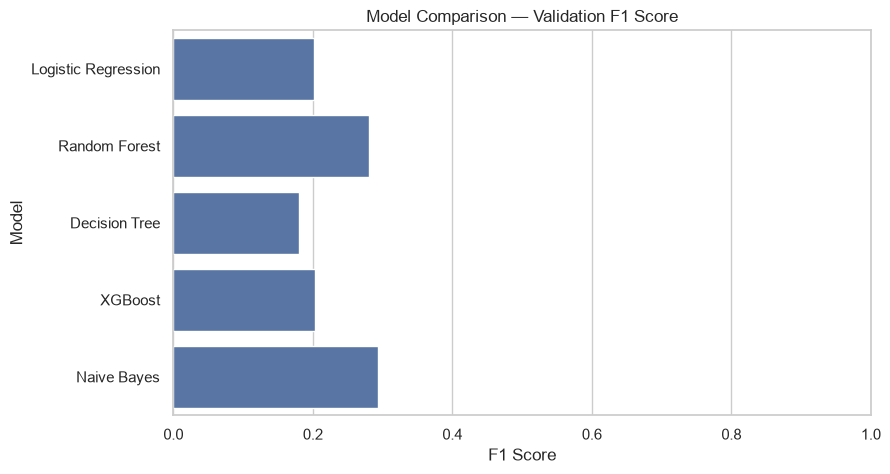

In [56]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="F1 Score", y="Model")
plt.title("Model Comparison — Validation F1 Score")
plt.xlabel("F1 Score")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.show()

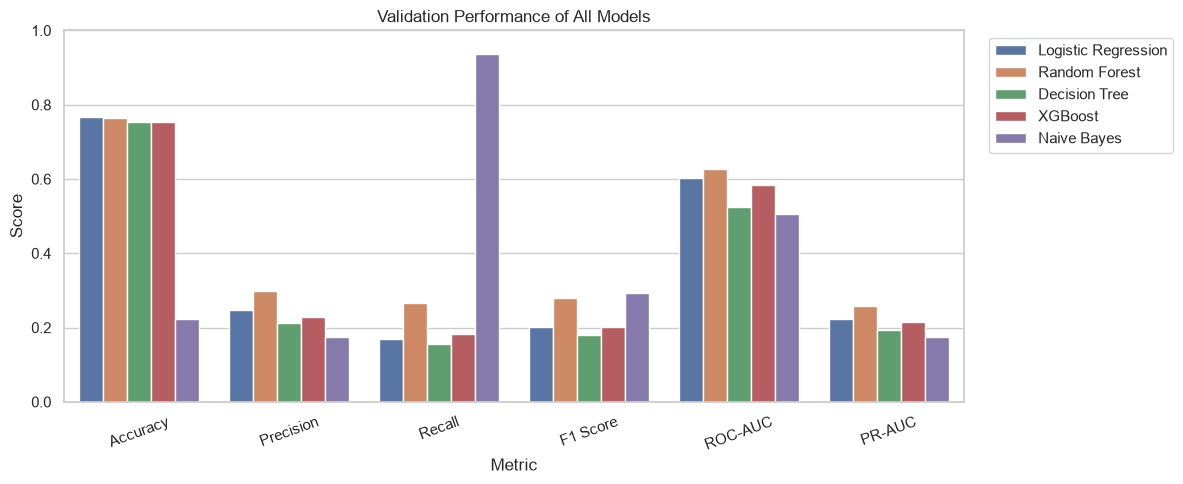

In [57]:
metrics_long = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 5))
sns.barplot(data=metrics_long, x="Metric", y="Score", hue="Model")
plt.title("Validation Performance of All Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

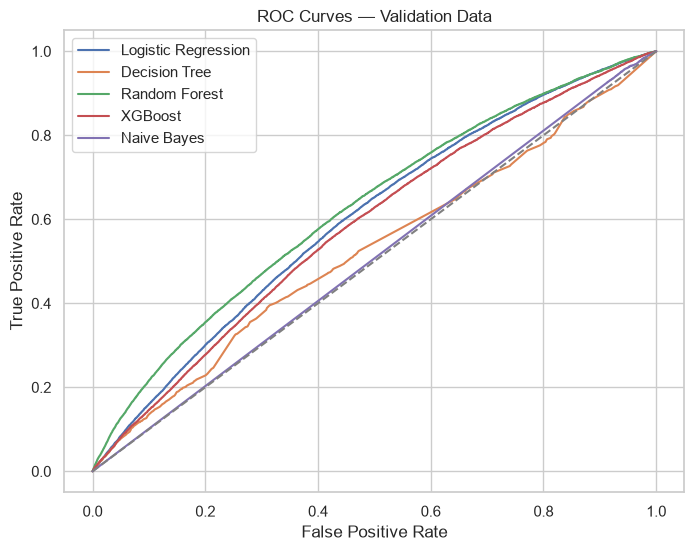

In [58]:
plt.figure(figsize=(8, 6))

for name in models:
    fpr, tpr, thresholds = roc_curve(
        y_val,
        validation_probabilities[name]
    )
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Validation Data")
plt.legend()
plt.show()

In [59]:
                                                                              
eligible_models = results_df[results_df["Accuracy"] >= MIN_ACCURACY]

if len(eligible_models) > 0:
    selected_row = eligible_models.sort_values(
        ["F1 Score", "Recall"], ascending=False
    ).iloc[0]
else:
    selected_row = results_df.sort_values(
        ["Accuracy", "F1 Score"], ascending=False
    ).iloc[0]

best_model_name = selected_row["Model"]
best_model = models[best_model_name]
best_threshold = float(selected_row["Threshold"])

print("Selected model:", best_model_name)
print("Validation accuracy:", round(selected_row["Accuracy"], 4))
print("Validation F1-score:", round(selected_row["F1 Score"], 4))
print("Selected threshold:", round(best_threshold, 2))

Selected model: Random Forest
Validation accuracy: 0.7649
Validation F1-score: 0.2806
Selected threshold: 0.17


In [60]:
best_val_prob = validation_probabilities[best_model_name]

threshold_results = []

for threshold in thresholds_to_check:
    predictions = (best_val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1 Score": f1_score(y_val, predictions, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.10,0.3477,0.1933,0.8767,0.3168
1,0.11,0.4284,0.2040,0.7970,0.3249
2,0.12,0.5017,0.2141,0.7070,0.3287
3,0.13,0.5649,0.2253,0.6244,0.3312
4,0.14,0.6201,0.2352,0.5338,0.3266
...,...,...,...,...,...
76,0.86,0.8275,0.0000,0.0000,0.0000
77,0.87,0.8275,0.0000,0.0000,0.0000
78,0.88,0.8275,0.0000,0.0000,0.0000
79,0.89,0.8275,0.0000,0.0000,0.0000


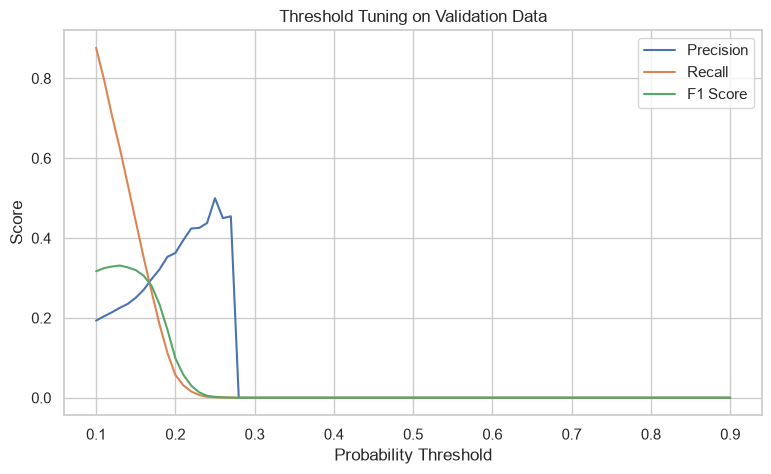

In [61]:
plt.figure(figsize=(9, 5))
plt.plot(threshold_df["Threshold"], threshold_df["Precision"], label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], label="Recall")
plt.plot(threshold_df["Threshold"], threshold_df["F1 Score"], label="F1 Score")
plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.title("Threshold Tuning on Validation Data")
plt.legend()
plt.show()

In [62]:
print("Selected model:", best_model_name)
print("Selected threshold:", round(best_threshold, 2))
print("Validation F1-score:", round(
    f1_score(y_val, (best_val_prob >= best_threshold).astype(int), zero_division=0), 4
))

Selected model: Random Forest
Selected threshold: 0.17
Validation F1-score: 0.2806


In [63]:
y_test_prob = best_model.predict_proba(X_test_encoded)[:, 1]
y_test_pred = (y_test_prob >= best_threshold).astype(int)

print("Final selected model:", best_model_name)
print("Test rows:", len(y_test))

Final selected model: Random Forest
Test rows: 96759


In [64]:
final_metrics = {
    "Model": best_model_name,
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test, y_test_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_test_prob),
    "PR-AUC": average_precision_score(y_test, y_test_prob)
}

final_metrics_df = pd.DataFrame([final_metrics])
display(final_metrics_df.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Random Forest,0.17,0.7046,0.3253,0.3419,0.3334,0.6277,0.306


In [65]:
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Not Delayed", "Delayed"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

 Not Delayed       0.82      0.80      0.81     75852
     Delayed       0.33      0.34      0.33     20907

    accuracy                           0.70     96759
   macro avg       0.57      0.57      0.57     96759
weighted avg       0.71      0.70      0.71     96759



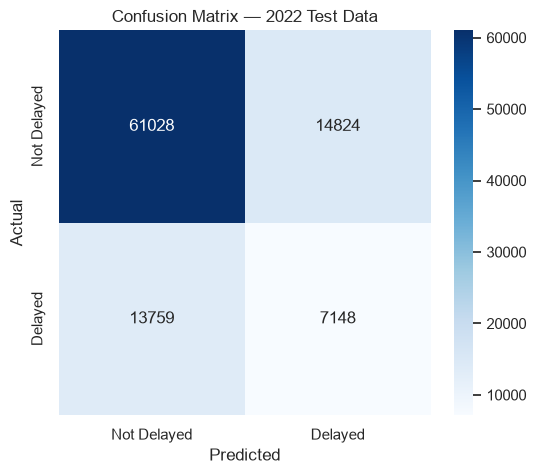

In [66]:
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Delayed", "Delayed"],
    yticklabels=["Not Delayed", "Delayed"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — 2022 Test Data")
plt.show()

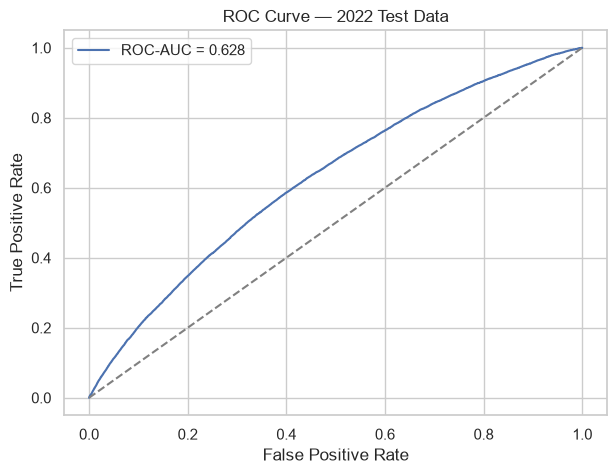

In [67]:
fpr, tpr, thresholds = roc_curve(y_test, y_test_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {final_metrics['ROC-AUC']:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — 2022 Test Data")
plt.legend()
plt.show()

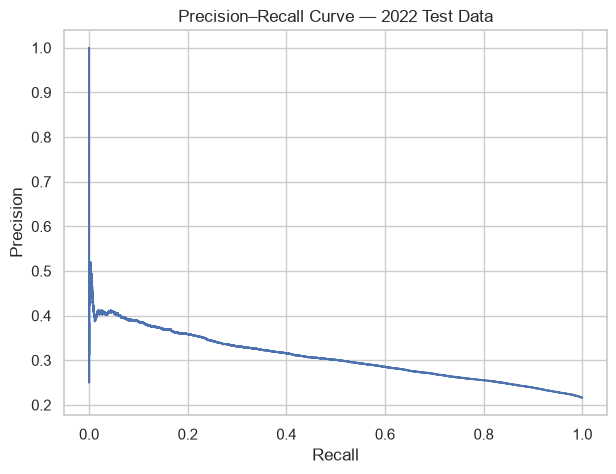

In [68]:
precision, recall, thresholds = precision_recall_curve(y_test, y_test_prob)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — 2022 Test Data")
plt.show()

,Feature,Importance
2,Year,0.167539
8,DepHour,0.091005
12,DepHourSin,0.083235
10,ArrHour,0.054200
6,DayOfYear,0.049252
808,DepPeriod_Morning,0.044428
807,DepPeriod_Evening,0.039777
13,DepHourCos,0.028361
15,MonthCos,0.026276
3,Month,0.024938


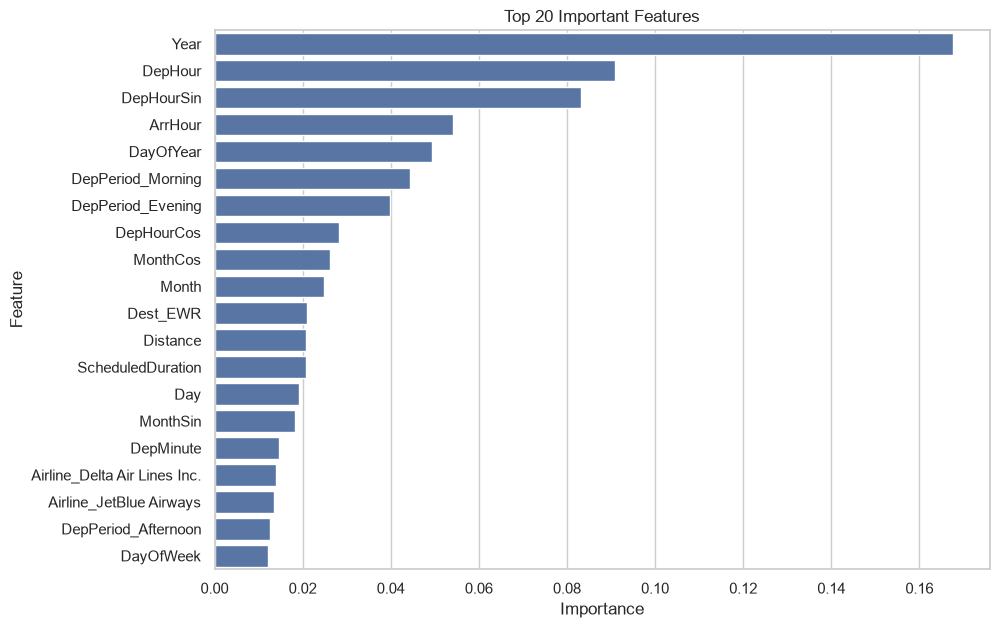

In [69]:
if best_model_name in ["Decision Tree", "Random Forest", "XGBoost"]:
    feature_importance = pd.DataFrame({
        "Feature": X_train_encoded.columns,
        "Importance": best_model.feature_importances_
    })

    feature_importance = feature_importance.sort_values(
        "Importance",
        ascending=False
    ).head(20)

    display(feature_importance)

    plt.figure(figsize=(10, 7))
    sns.barplot(
        data=feature_importance,
        x="Importance",
        y="Feature"
    )
    plt.title("Top 20 Important Features")
    plt.show()
else:
    print("The selected model does not provide tree feature_importances_.")

In [70]:
majority_class = y_train.value_counts().idxmax()
baseline_predictions = np.full(len(y_test), majority_class)

print("Majority class:", majority_class)
print("Baseline accuracy:", round(accuracy_score(y_test, baseline_predictions), 4))
print("Selected model accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Selected model F1-score:", round(f1_score(y_test, y_test_pred, zero_division=0), 4))

Majority class: 0
Baseline accuracy: 0.7839
Selected model accuracy: 0.7046
Selected model F1-score: 0.3334


In [71]:
REPORT_PATH.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    REPORT_PATH / "validation_model_comparison.csv",
    index=False
)

threshold_df.to_csv(
    REPORT_PATH / "validation_threshold_results.csv",
    index=False
)

final_metrics_df.to_csv(
    REPORT_PATH / "final_2022_test_metrics.csv",
    index=False
)

print("Model comparison and evaluation results saved.")

Model comparison and evaluation results saved.


In [72]:
deployment_bundle = {
    "model": best_model,
    "model_name": best_model_name,
    "threshold": float(best_threshold),
    "features": FEATURES,
    "categorical_features": categorical_features,
    "numerical_features": numerical_features,
    "numeric_imputer": numeric_imputer,
    "scaler": scaler,
    "categorical_imputer": categorical_imputer,
    "training_columns": list(X_train_encoded.columns),
    "final_metrics": {
        "Accuracy": float(final_metrics["Accuracy"]),
        "Precision": float(final_metrics["Precision"]),
        "Recall": float(final_metrics["Recall"]),
        "F1 Score": float(final_metrics["F1 Score"]),
        "ROC-AUC": float(final_metrics["ROC-AUC"]),
        "PR-AUC": float(final_metrics["PR-AUC"])
    },
    "test_records": int(len(y_test))
}

joblib.dump(
    deployment_bundle,
    MODEL_PATH / "flightwise_deployment_bundle.joblib"
)

print("Selected model and deployment bundle saved successfully.")

Selected model and deployment bundle saved successfully.


In [73]:
print("FLIGHTWISE AI — FINAL MODEL SUMMARY")
print("------------------------------------")
print("Selected model:", best_model_name)
print("Training years: 2018, 2019, 2020")
print("Validation year: 2021")
print("Final test year: 2022")
print("Class balancing: Not applied; original class distribution retained")
print("Selected threshold:", round(best_threshold, 3))
print("Final test accuracy:", round(final_metrics["Accuracy"], 4))
print("Final test precision:", round(final_metrics["Precision"], 4))
print("Final test recall:", round(final_metrics["Recall"], 4))
print("Final test F1-score:", round(final_metrics["F1 Score"], 4))
print("Final test ROC-AUC:", round(final_metrics["ROC-AUC"], 4))
print("Final test PR-AUC:", round(final_metrics["PR-AUC"], 4))

FLIGHTWISE AI — FINAL MODEL SUMMARY
------------------------------------
Selected model: Random Forest
Training years: 2018, 2019, 2020
Validation year: 2021
Final test year: 2022
Class balancing: Not applied; original class distribution retained
Selected threshold: 0.17
Final test accuracy: 0.7046
Final test precision: 0.3253
Final test recall: 0.3419
Final test F1-score: 0.3334
Final test ROC-AUC: 0.6277
Final test PR-AUC: 0.306
